# **Task 2 — Optimised AI for Low-Cost Brain Tumor MRI Classification**


---


In this Task 2, will implement a code with the goal of testing the efficiency and speed of five different algorithms applied to the task of classifying images of brain tumors. The major goal of this stage is to analyze the performance of the algorithms in terms of evaluation metrics such as precision, recall, and F1-Score, as well as the efficiency in terms of training and evaluation/test time.

The different algorithms that will be assessed are CNN, MLP, EfficientNet, ResNet18, and ResNet50. All these models will be trained and then tested with the same dataset, in order to determine not only the accuracy of each approach in classifying images but also how quickly the models are able to perform the evaluation process.

The images will then be sorted into one of four pre-defined classes: Glioma, Meningioma, No Tumor, and Pituitary

The Databaset used: https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset



# **— Comprehensive Overview of Model Setup and Data Handling**










## **— Key Libraries and Their Roles in Model Development**

The following section outlines the libraries used in this project and for what purpose. These libraries range from data manipulation and neural network construction to visualization and form the very foundation of the workflow.

**NumPy:** Library to manipulate multidimensional arrays for efficient mathematical calculations. Often used for low-level mathematical operations that underpin libraries like PyTorch.

**Pillow (PIL):** Library for opening, manipulating, and saving images in many different formats.

**Torch:** Deep learning framework for building, training, and testing neural networks.
* torch: Manipulation of tensors and basic mathematical operations.
* torch.nn: Constructing neural network layers.
* torch.nn.functional: various useful functions such as activations (ReLU, Softmax) and tensor operations.
torch.optim: Optimizers like SGD and Adam to update the model weights during training.

**Torchvision:** Companion library for PyTorch for computer vision.

* torchvision: Helps give pre-trained datasets such as CIFAR-10 and ImageNet and also contains tools for data manipulation.
* transforms: Provides a way to apply preprocessing on images (for example, normalization, resizing).

**TMatplotlib:** A plotting library for creating graphs and visualizing data.

* pyplot: Submodule for quickly making graphs.

**Time**: By adding a tme, it will be possible to calculate the total training and testing duration for each algorithm, comparing the time efficiency between different models.

In [ ]:
# Importing required libraries
import numpy as np
from PIL import Image # For image manipulation
from torch.utils.data import WeightedRandomSampler # For resampling imbalanced data
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, accuracy_score # For calculating metrics

# Importing PyTorch and its core modules

import torch
import torch.nn as nn # For defining neural networks
import torch.nn.functional as F # For auxiliary functions, such as ReLU
import torch.optim as optim # For optimizers, such as SGD or Adam

# Importing PyTorch Vision for datasets and models
import torchvision
from torchvision import models
import matplotlib.pyplot as plt # For visualizing graphs and images
import torchvision.transforms as transforms # For image transformations
import time


## **— Connecting to Google Drive**
The very first two lines of code, from google.colab import drive and drive.mount('/content/drive'), are used to link the runtime with my personal Google Drive, allowing direct access to the files stored there. This comes in handy when loading my Kaggle dataset and saving results like checkpoints of trained models. Data is not permanent in Colab's local storage.

In [ ]:
# Using Google Drive to access the atabase
from google.colab import drive
drive.mount('/content/drive')

MessageError: Error: credential propagation was unsuccessful

### **— Pre-processing, Data Augmentation and Class Rebalancing**

This section is for loading and preprocessing brain tumour image data to be used for training and testing the model. It applies transformation to each image, organizes the data into batches, and also implements data augmentation and class rebalancing strategies. Listed below are the major steps described in the code.

**Data transformations:** Resized to 32x32 pixels.

**Data Augmentation:**
* Random horizontal flip with 50% probability.
* Random rotation of up to 15 degrees, brightness, contrast, saturation, and hue adjustments.
* Converting to tensors and normalized with mean (0.5, 0.5, 0.5) and standard deviation (0.5, 0.5, 0.5) for standardization.

**Defining the routes and Loading Database:**
* It has the training and test datasets saved in Google Drive; their paths are defined in variables train_path and test_path, respectively.
* Using torchvision.datasets.ImageFolder to load images and their labels automatically while applying defined transformation.

**Class Rebalancing:**

* Counting the number of instances for each class in the training data set.
* Calculating inverse weights for each class, where more weight is given to classes with fewer examples.
* Applying oversampling with WeightedRandomSampler to balance class frequency at training time.

**Grouping data into batches:**
* Creating a DataLoader for the training data with the rebalanced sampler.
* Organizaing the data into batches of 12 images, and shuffles the examples, using two worker processes to optimize loading (num_workers=2).

**Define classes:** The output classes of the model are mapped to the class names: Glioma, Meningioma, NoTumor, Pituitary.

**Creating a Structure to Store Results:** Creating a dictionary to store the losses (loss_values) for each algorithm:

In [ ]:
# Define transformations for pre-processing images
transform = transforms.Compose([
    transforms.Resize((32, 32)),                     # Resizes images to 32x32
    transforms.RandomHorizontalFlip(p=0.5),          # Applies random horizontal flip with 50% probability
    transforms.RandomRotation(15),                   # Randomly rotates up to 15 degrees
    transforms.ColorJitter(brightness=0.2,           # Adjusts brightness, contrast, saturation and hue
                           contrast=0.2,
                           saturation=0.2,
                           hue=0.1),
    transforms.ToTensor(),                           # Convert image to tensor
    transforms.Normalize((0.5, 0.5, 0.5),            # Normalize R, G and B channels
                         (0.5, 0.5, 0.5))
])

# Sets the batch size for training and testing
batch_size = 64


# Paths to training and testing sets in Google Drive
train_path = '/content/drive/MyDrive/Brain Tumor/Training'
test_path = '/content/drive/MyDrive/Brain Tumor/Testing'

# Load the training and testing data with the defined transformations
train_data = torchvision.datasets.ImageFolder(root=train_path, transform=transform)
test_data = torchvision.datasets.ImageFolder(root=test_path, transform=transform)


# Class rebalancing: WeightedRandomSampler
class_counts = [0] * len(train_data.classes)  #Count images by class
for label in train_data.targets:  #Iterates directly over labels
    class_counts[label] += 1

# Calculate inverse weights for each class
class_weights = 1. / torch.tensor(class_counts, dtype=torch.float)
sample_weights = [class_weights[label] for label in train_data.targets]

# Create the sampler for oversampling
sampler = WeightedRandomSampler(weights=sample_weights,
                                num_samples=len(train_data),
                                replacement=True)

# DataLoaders with sampler for rebalancing

train_loader = torch.utils.data.DataLoader(train_data, batch_size=12, shuffle=True, num_workers=0)
test_loader = torch.utils.data.DataLoader(test_data, batch_size=12, shuffle=True, num_workers=0)

# Classes Names
classes_names = ('Glioma', 'Meningioma', 'NoTumor', 'Pituitary')

# View the first image of the training set
image, label = train_data[0]
print(f"Image Size: {image.size()} - Class: {classes_names[label]}")

training_results = {
    "CNN": [],
    "MLP": [],
    "EfficientNet": [],
    "ResNet50": [],
    "ResNet18": [],
}

# **— Convolutional Neural Network (CNN): Architecture and Implementation**

## **— CNN: Defining the Neural Network Architecture**

This code section defines the architecture of a convolutional neural network (CNN) using the PyTorch library, this custom neural network is called NeuralNet and will perform image classification tasks.

**Network Components:**
1.   **Convolutional Layers (conv1 and conv2):**
 *   **conv1:** First convolutional layer with 3 input channels (RGB) and 12 filters of size 5x5.
 *  **conv2:** Second convolutional layer with 12 input channels (output of conv1) and 24 filters of size 5x5.
2. **Pooling Layer**
 *    After each convolutional layer, the spatial dimensions (height and width) are cut in half using MaxPooling with a 2x2 window.
3. **Fully Connected Layers**
 *   **fc1:** Connects the flattened data from the output of the convolutional layers to 120 neurons.
 *   **fc2:** Connects the 120 neurons of fc1 to 84 neurons.
 *   **fc3:** Connects the 84 neurons of fc2 to the output layer, which has 10 neurons.
**Forward Method:**

Explains the network's data flow, or how input data moves between the layers:
1.  The ReLU activation function and pooling are applied when the images enter the convolutional layers (conv1 and conv2).
2.  Torch.flatten is used to flatten (make 1D) the data.
3.  Once more using ReLU in the first two, they move through the fully connected layers (fc1, fc2, and fc3).
4.  The values of the final layer (fc3), which represent the probabilities for the ten classes, are returned in the final output.


In [ ]:
# Defining the CNN Architecture
class NeuralNet(nn.Module):
    def __init__(self):
        super().__init__()
        # Convolution layer 1: Converts the input image (3 RGB channels) to 12 feature maps
        self.conv1 = nn.Conv2d(3, 12, 5)# Input: 3 channels (RGB), Output: 12 maps, Kernel size 5x5
        # Pooling layer: Downsamples the image (halving the height and width)
        self.pool = nn.MaxPool2d(2, 2)# Kernel size 2x2, stride 2 (halving the dimension)

        # Convolution layer 2: Increase the number of feature maps from 12 to 24
        self.conv2 = nn.Conv2d(12, 24, 5)# Input: 12 maps, Output: 24 maps, Kernel size 5x5

        # Fully connected layer 1: "Flattens" the output of the convolution layer to be processed by dense layers
        # The input has 24 5x5 maps, so the number of inputs will be 24*5*5 = 600
        self.fc1 = nn.Linear(24 * 5 * 5, 120) # From 600 neurons to 120 neurons

        # Fully connected layer 2: Reduce the number of neurons from 120 to 84
        self.fc2 = nn.Linear(120, 84)# From 120 neurons to 84 neurons

        # Fully connected layer 3: Connects the last layer of 84 neurons to the output layer (4 classes)
        # The output layer has 4 neurons, corresponding to 4 classes: Glioma, Meningioma, NoTumor, Pituitary
        self.fc3 = nn.Linear(84, len(classes_names))  # Output with the number of classes

# Defining the network forward pass
    def forward(self, x):

        x = self.pool(F.relu(self.conv1(x)))      # Apply the first convolution and the ReLU function for activation, then perform pooling (dimension reduction)
        x = self.pool(F.relu(self.conv2(x)))      # Apply second convolution, ReLU function and pooling again

      # Flatten the pooling output to a one-dimensional vector (required for fully connected layers)
        x = torch.flatten(x, 1)
        x = F.relu(self.fc1(x)) # Go through the first fully connected layer, apply ReLU for activation
        x = F.relu(self.fc2(x)) # Go through the second fully connected layer, apply ReLU

      # Pass through the final output layer
        x = self.fc3(x)

        return x

## **— CNN:  Training Process and Model Optimization**
This section implements the training process, during every epoch, the network changes its weights to decrease the loss, which makes the network more efficient in its classification task. The training basically consists of three major steps: model preparation, hyperparameter configuration, and execution of the training loop.

**Model Preparation**

The model is initiated as net = NeuralNet(), and the loss function is CrossEntropyLoss() because it is a multi-class classification problem. It merges the log-softmax operation with the cross-entropy loss to calculate a loss between the network's predictions and the true labels. Optimizer: Stochastic Gradient Descent (SGD) - Learning rate: 0.001; Momentum: 0.9. These two parameters are important to control the speed and stability of the learning.

**Training Loop Execution**

Training happens in a loop, which runs 50 epochs. An epoch is a full cycle on the training data. In an epoch:

* The code will iterate over the batches of data given by train_loader. The
batch will be a tuple of the inputs and their labels.
* The gradients of the optimizer are zeroed out using optimizer.zero_grad() to avoid accumulating values from previous steps.
* The network processes the data in a forward pass, making predictions - which can be referred to as outputs - that are then compared to the true labels through the loss function. The subsequent error is computed and stored.
* The backward pass, where the gradients of the error concerning the weights of the network will be computed with loss.backward().
* The optimizer takes the gradients and updates the weights of the network using optimizer.step().

At the end of each batch, the value of loss is added to the running_loss variable. Once all batches have been processed, the average epoch loss is calculated and shown.

**Performance Monitoring**

This helps in monitoring efficiency while training: every epoch displays the average loss in the end, Training Loss: {running_loss / len(train_loader):.4f} continues to reduce every time, it shows the model learns to map the inputs correctly to their respective outputs, thus reducing and moving closer to the goal of minimizing the global error.

The iterative loop means that at each epoch, the model fine-tunes parameters with the view of optimizing the performance in classification.



In [ ]:
# Instantiating the Neural Network
net = NeuralNet()  # Use the NeuralNet class (or other defined architecture)
loss_function = nn.CrossEntropyLoss()
optimizer = optim.SGD(net.parameters(), lr=0.001, momentum=0.9)

# Training the Algorithm and Saving the Results
algorithm_name = "CNN"  # Update this for each algorithm if necessary
loss_values = []

# Measure training time
start_train_time = time.time()  # Record the start time

# Training loop
for epoch in range(40):  # Adjust the number of epochs as needed
    print(f"Training epoch {epoch + 1}...")
    running_loss = 0.0

    for i, data in enumerate(train_loader):
        inputs, labels = data
        optimizer.zero_grad()  # Reset gradients

        outputs = net(inputs)  # Use 'net' to call the model, not 'mlp_model'
        loss = loss_function(outputs, labels)  # Compute the loss
        loss.backward()  # Backpropagate the gradients
        optimizer.step()  # Update the weights

        running_loss += loss.item()  # Accumulate the loss

    # Average loss per epoch
    avg_loss = running_loss / len(train_loader)
    loss_values.append(avg_loss)  # Add the average loss to the list
    print(f"Epoch {epoch + 1} Loss: {avg_loss:.4f}")

# Measure total training time
end_train_time = time.time()  # Record the end time
train_time = end_train_time - start_train_time  # Calculate total training time
print(f"Total Training Time: {train_time:.2f} seconds")

Training epoch 1...
Epoch 1 Loss: 1.3775
Training epoch 2...
Epoch 2 Loss: 1.2556
Training epoch 3...
Epoch 3 Loss: 1.0633
Training epoch 4...
Epoch 4 Loss: 0.8966
Training epoch 5...
Epoch 5 Loss: 0.7482
Training epoch 6...
Epoch 6 Loss: 0.6723
Training epoch 7...
Epoch 7 Loss: 0.6185
Training epoch 8...
Epoch 8 Loss: 0.5787
Training epoch 9...
Epoch 9 Loss: 0.5503
Training epoch 10...
Epoch 10 Loss: 0.5178
Training epoch 11...
Epoch 11 Loss: 0.4966
Training epoch 12...
Epoch 12 Loss: 0.4767
Training epoch 13...
Epoch 13 Loss: 0.4525
Training epoch 14...
Epoch 14 Loss: 0.4265
Training epoch 15...
Epoch 15 Loss: 0.3967
Training epoch 16...
Epoch 16 Loss: 0.3836
Training epoch 17...
Epoch 17 Loss: 0.3867
Training epoch 18...
Epoch 18 Loss: 0.3601
Training epoch 19...
Epoch 19 Loss: 0.3465
Training epoch 20...
Epoch 20 Loss: 0.3214
Training epoch 21...
Epoch 21 Loss: 0.3109
Training epoch 22...
Epoch 22 Loss: 0.2974
Training epoch 23...
Epoch 23 Loss: 0.2793
Training epoch 24...
Epoch 24

KeyboardInterrupt: 

In [ ]:
# Salvar os resultados de treinamento
training_results[algorithm_name] = loss_values

## **— CNN: Display of the Training Loss as a Graphic**

This section  shows the evolution of training loss of CNN during different epochs of the current algorithm in train. In this, every epoch represents one full pass over the training dataset, and the loss as a metric is representative of how well the model is doing to that end.

The trend seen in the graph gives an idea about the model learning process: its slope indicates that it has seen proper training while converging to a low loss. The chart is also saved to a file with a unique filename including the name of the algorithm, which is useful to identify and compare models easily in your project.

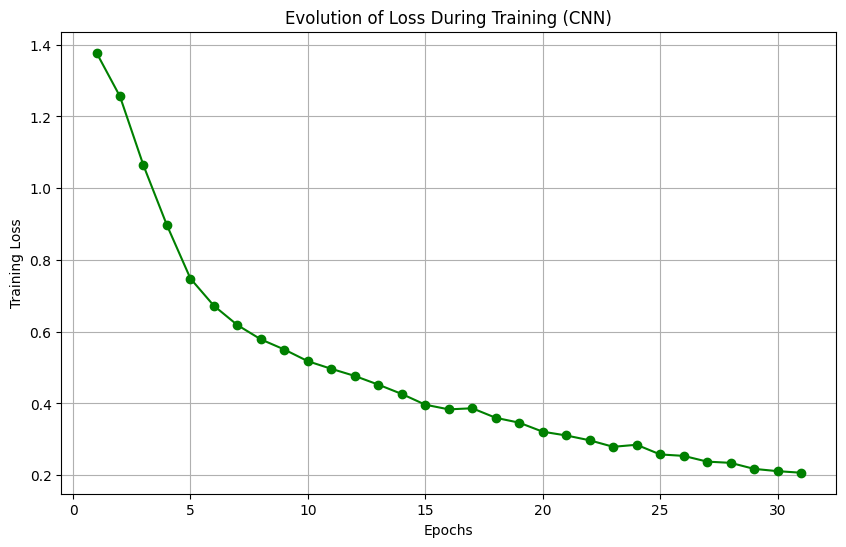

In [ ]:
# Criar o gráfico
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(loss_values) + 1), loss_values, marker='o', linestyle='-', color='g')

plt.title(f'Evolution of Loss During Training ({algorithm_name})')
plt.xlabel('Epochs')
plt.ylabel('Training Loss')
plt.grid(True)

# Salvar o gráfico
plt.savefig(f"training_loss_{algorithm_name}.png")
plt.show()

## **— CNN: Saving and Loading a Trained Neural Network**

This section shows how to save the state of a neural network's parameters after training and how to reload them later on. This can be useful for reusing the model without having to retrain it, which takes much time and computational resources.

In [ ]:
# Save the trained model
torch.save(net.state_dict(), f"{algorithm_name}_trained_model.pth")
print(f"{algorithm_name} Model saved.")

# Load the saved model
net = NeuralNet()

# Corrected: Use the dynamic model path based on the algorithm name
model_path = f"/content/{algorithm_name}_trained_model.pth"  # Construct the path based on algorithm_name
net.load_state_dict(torch.load(model_path, weights_only=True))  # Load only the model weights
net.eval()  # Put the model into evaluation mode

print(f"{algorithm_name} model loaded successfully and ready for evaluation!")

## **— CNN: Evaluation and Testing of CNN Model**

This section evaluates the performance of the model fitted on a test set using some standard metrics of machine learning. The above code performs a validation without updating model parameters.


**Evaluation**

The model is set to testing mode by calling net.eval(). This configuration eliminates modules such as dropout and batch normalization, which by default introduces randomness in predictions. Evaluation is done under a with torch.no_grad() block, which stops the computation of gradients to save memory and to accelerate processes.

**Test Data Processing**
The code loops over test_loader data, which has organised the test set into batches. For every batch:
1. The actual images and labels are extracted **-images and labels.**
2. The model performs a prediction with outputs = net(images). The result - outputs - includes the predicted probabilities for each class.
3. Then it uses the torch.max(outputs.data, 1) to pick the class with the highest probability and returns the index of the most likely class as its final prediction.

The model's predictions are compared to the real labels, adding up the amount of hits in correct and the sum of all processed labels into total. At the same time, the actual labels (labels) and the predictions (forecasted) are stored in all_labels and all_predictions lists, respectively, to later compute the global metrics.


In [ ]:
# Testing & Metrics

# Timer for evaluation/testing
start_test_time = time.time()  # Mark the start time

correct = 0
total = 0
all_labels = []        # To store all the true labels
all_predictions = []   # To store all the predictions made by the model

net.eval()
with torch.no_grad():
    for data in test_loader:
        images, labels = data
        outputs = net(images)
        _, predicted = torch.max(outputs.data, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

        all_labels.extend(labels.tolist())
        all_predictions.extend(predicted.tolist())

end_test_time = time.time()  # Mark the end time
test_time = end_test_time - start_test_time  # Calculate the total evaluation time
print(f"Total Test Time for CNN: {test_time:.2f} seconds")


## —  **CNN: Calculating Metrics**

In this section, it shows the performance evaluation of the CNN model by calculating key metrics such as accuracy, precision, recall, and F1-score, which are derived from the confusion matrix.

These metrics help assess the model's effectiveness in making predictions across different classes. Additionally, we will examine the model's efficiency by analyzing the total number of parameters, which gives insight into its complexity and potential computational demands when deployed on various devices.

**Model Performance Metrics**

Using the pre-computed lists of real labels and any predictions:
* **Accuracy:** It describes the share of properly predicted events from all cases.
* **Precision, Recall, F1-Score:** These metrics are derived from the confusion matrix; their values are computed with the argument average='weighted' to account for class distribution in order not to let the results be too much influenced by the largest classes.
* **Confusion Matrix:** It shows the number of correct and incorrect predictions for each class, enabling the identification of the pattern of model error.

**Model Efficiency**

To complement the analysis, the code calculates and displays the total number of model parameters. This metric, num_parameters, reflects the complexity of the model and its potential impact on computational performance and efficiency on different devices.

In [ ]:
accuracy = accuracy_score(all_labels, all_predictions)
precision = precision_score(all_labels, all_predictions, average='weighted')
recall = recall_score(all_labels, all_predictions, average='weighted')
f1 = f1_score(all_labels, all_predictions, average='weighted')
conf_matrix = confusion_matrix(all_labels, all_predictions)

# Display final metrics
print("\nFinal Performance Metrics:")
print(f"Test Accuracy: {accuracy * 100:.2f}% - The percentage of correct predictions made by the model during testing.")
print(f"Precision: {precision:.4f} - Measures how many positive predictions the model made that were actually correct (e.g., correctly identified tumors).")
print(f"Recall: {recall:.4f} - Measures the model's ability to find all the actual positive cases (e.g., all tumors that should have been identified).")
print(f"F1-Score: {f1:.4f} - A balance between Precision and Recall, providing an overall measure of the model's performance.")
print("Confusion Matrix: Shows the number of correct and incorrect predictions made for each class of tumor.")
print(conf_matrix)  # Displays the confusion matrix


# Métrica de eficiência (exemplo simples)
num_parameters = sum(p.numel() for p in net.parameters())
print(f"Number of Model Parameters: {num_parameters}")

## **— CNN: Performing Inference on a Single Image**

This section  performs inference on a single image using the trained model. It processes the image to match the input to the neural network, makes the prediction, and displays both the predicted class and the original image.

**Image Transformation for Inference**
The load_image function applies a series of transformations necessary to prepare the image before feeding it to the model:

* **Resizing:** Resizes the image to (32, 32) pixels by using transforms.Resize. This size should match the dimensions expected by the neural network.

* **To Tensor:** The transforms.ToTensor() transform changes the image from some sort of pixel format, where values usually lie between 0 and 255, into a PyTorch tensor with values between 0 and 1.

* **Normalization:**
The transforms.Normalize normalizes the image so that all values ​​in each channel (RGB) have a mean of 0.5 and a standard deviation of 0.5. These should match the numbers used during training.

* **Add Extra Dimension:**
The image tensor that results is expanded by image.unsqueeze(0) to add a batch dimension (batch size of 1). This is because all PyTorch models expect data to have an extra dimension for batches.


**Loading and Inference**

The image path is specified in image_path, and the image is loaded and preprocessed with the load_image function.

**Image Display and Prediction**

Then, the original image is reloaded using Image.open and displayed using the matplotlib library; the axes are removed for better visualization. Model prediction translates into the corresponding class using classes_names mapping and displays on the console.



In [ ]:
new_transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

def load_image(image_path):
  image = Image.open(image_path).convert("RGB")
  image = new_transform(image)
  image = image.unsqueeze(0)
  return image

image_path = '/content/drive/MyDrive/Test2.jpg'

# Load the single image using the correct path
image = load_image(image_path)

# Run the model in evaluation mode
net.eval()
with torch.no_grad():
    output = net(image)
    _, predicted = torch.max(output, 1)

img = Image.open(image_path)  # Reload the original image for display
plt.imshow(img)
plt.axis('off')  # Disable axes for better visualization
plt.show()

# Print the predicted class
print(f"\n The Predicted Class is: {classes_names[predicted.item()]}")

# **— Multilayer Perceptron (MLP): Architecture and Application**

## **— MLP: Architecture and Application**

MLP is a neural network model that operates primarily on tabular data or feature vectors (flattened data). It is composed of fully connected layers, where each neuron in one layer connects to all neurons in the next. In the case of images, the images are converted to a one-dimensional vector.

**MLP Class**

The MLP class inherits from nn.Module, which is the basis for all neural networks in PyTorch. The architecture is composed of several densely connected layers.

**Init Constructor**

The __init__ method initializes the network's layers. It defines the following:

1. **Layers defined:**
* **fc1:** First full-connected layer with 3072 inputs and 1024 outputs.
  * The 3072 input neurons come from the input image size, which is 32x32 pixels in 3 channels (RGB):  **3 x 32 x 32= 3072**
  * The 1024 neurons were arbitrarily chosen as the size of the first hidden layer.
* **fc2:** This is the second hidden layer with 1024 inputs (outputs of the previous layer) and 512 outputs.
* **fc3**: This is the third hidden layer with 512 inputs and 256 outputs.
* **fc4**: This is the output layer with 256 inputs and a number of outputs equal to the number of classes, len(classes_names), which in this case is 4.

These layers transform the input data, images, from their raw form to a form that could be used for classification into the 4 classes.

**Forward Method**

The forward method describes how the data will flow through the network. The process of the forward pass occurs when we feed an image.

1. **Flatten (torch.flatten):**
  * Input images are in the format [batch_size, channels, height, width], or [batch_size, 3,32,32]
  * The torch.flatten(x, 1), which turns each image into a one-dimensional vector with 3072 elements, prepares the input needed for the first dense layer.

2. **FReLU Activation (F.relu):**
  * After every hidden layer, i.e., fc1, fc2, and fc3, the ReLU or Rectified Linear Unit activation function is used.
  * ReLU introduces non-linearity, which allows the model to learn more complex representations.

**Output Layer (fc4):**

The last layer fc4, maps the 256 neurons to 4 outputs, corresponding to the 4 classification classes. Note that this layer does not use an activation function in the code since normally the softmax or log-softmax function would be applied outside in the loss calculation or during inference.


In [ ]:
# Defining the MLP architecture
class MLP(nn.Module):
    def __init__(self):
        super(MLP, self).__init__()
        # Inut layer: 3 (RGB) * 32 * 32 = 3072 input neurons
        # Using 3 hidden layers with different numbers of neurons
        self.fc1 = nn.Linear(3 * 32 * 32, 1024)  # First hidden layer with 1024 neurons
        self.fc2 = nn.Linear(1024, 512)          # Second hidden layer with 512 neurons
        self.fc3 = nn.Linear(512, 256)           # Third hidden layer with 256 neurons
        self.fc4 = nn.Linear(256, len(classes_names))  # Output layer with 4 neurons (one for each class)

    def forward(self, x):
        # Flatten the input image (converting from 3x32x32 to 3072)
        x = torch.flatten(x, 1)

        # Pass through the hidden layers and apply ReLU activation function
        x = F.relu(self.fc1(x))  # Apply ReLU after the first hidden layer
        x = F.relu(self.fc2(x))  # Apply ReLU after the second hidden layer
        x = F.relu(self.fc3(x))  # Apply ReLU after the third hidden layer

        # Pass through the final output layer (no activation function, logits)
        x = self.fc4(x)
        return x


## **— MLP: Initializing the Model, Loss Function, and Optimizer**

In this section, it instantiates an MLP model, defines the loss function, and sets up the optimizer to perform the training.

**Instantiating the MLP Model**

An instance of the MLP model, previously defined as a class, was created. The line **mlp_model = MLP()** instantiates an MLP neural network with a previously described architecture of fully connected layers. Now, object mlp_model holds the network prepared to be trained, meaning that its layers and parameters - weights, and biases - are defined.

**Defining the Loss Function**

It basically measures how good or bad the model's prediction is compared to the real classes of the data. CrossEntropy Loss is used for multi-class classification problems and calculates the "loss" between the model's prediction-the predicted probabilities-and: the real class. The lower the loss, the more accurate the model will be.

*   **Cross-Entropy Loss** is a very standard loss function in classification problems, mostly in multi-class classification tasks. This calculates the "error" between what the model predicted and the correct answer, penalizing more when the prediction is too far from the true answer.

**Setting Up the Optimizer**

Here, it is setting up the optimizer in order to train the network. It will update the model weights according to the loss function.



In [ ]:
# Instantiating the MLP model
mlp_model = MLP()

# Using the same loss function and optimizer
# CrossEntropyLoss is commonly used for multi-class classification problems.
loss_function = nn.CrossEntropyLoss()

# Stochastic Gradient Descent (SGD) optimizer is used here with a learning rate of 0.001
# The momentum helps accelerate gradients in the right directions, improving convergence
optimizer = optim.SGD(mlp_model.parameters(), lr=0.001, momentum=0.9)



## **— MLP: Training Process and Model Optimization**

This section is very similar to CNN model training, with only a few changes related to the MLP architecture. One key difference lies in the fact that algorithm_name has been set to "MLP"-as a flag indicating that we are training the Multi-Layer Perceptron model in this case-and the training_results dictionary has been updated to store loss values from the MLP model for later use when creating the corresponding training loss graph.

In [ ]:
# Training the Algorithm and Saving the Results
algorithm_name = "MLP"  # Update this for each algorithm
loss_values = []

# Timer for the evaluation/testing
start_test_time = time.time()  # Marks the start time of the training process

# Training loop
for epoch in range(50):  # Adjust to the desired number of epochs
    print(f"Training epoch {epoch + 1}...")
    running_loss = 0.0

    for i, data in enumerate(train_loader):
        inputs, labels = data
        optimizer.zero_grad()  # Reset gradients

        outputs = net(inputs)  # Use 'net' (the model) instead of 'mlp_model'
        loss = loss_function(outputs, labels)  # Compute the loss
        loss.backward()  # Backpropagate the gradients
        optimizer.step()  # Update weights

        running_loss += loss.item()  # Accumulate the loss

    # Average loss per epoch
    avg_loss = running_loss / len(train_loader)
    loss_values.append(avg_loss)  # Add the average loss to the list
    print(f"Epoch {epoch + 1} Loss: {avg_loss:.4f}")

# Measure total training time
end_train_time = time.time()  # Record the end time
train_time = end_train_time - start_test_time  # Calculate total training time
print(f"Total Training Time: {train_time:.2f} seconds")


## **— MLP: Saving the Model**


In [ ]:
# Salvar os resultados de treinamento
training_results[algorithm_name] = loss_values

## **— MLP: Display of the Training Loss as a Graphic**

This section generates and saves a graph to visualize the training loss evolution over the epochs of the MLP model. It entitles a graph entitled **"Evolution of Loss During Training (MLP)"**, dynamically updated based on the current algorithm name, to ensure each model plot is appropriately labeled. Once the graph is generated, it is saved using a unique filename that includes the model name, such as training_loss_MLP.png, for easy identification.

In [ ]:
# Create graph for current algorithm
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(loss_values) + 1), loss_values, marker='o', linestyle='-', color='b')

plt.title(f'Evolution of Loss During Training ({algorithm_name})')
plt.xlabel('Epochs')
plt.ylabel('Training Loss')
plt.grid(True)

# Save the chart with a unique name
plt.savefig(f"training_loss_{algorithm_name}.png")
plt.show()

In [ ]:
# Salva o modelo treinado
torch.save(mlp_net.state_dict(), f"{algorithm_name}_trained_model.pth")
print(f"{algorithm_name} Model saved.")

# Carregar o modelo salvo
mlp_net = MLP()

# Corrigido: Usando o caminho dinâmico do modelo com base no nome do algoritmo
model_path = f"/content/{algorithm_name}_trained_model.pth"  # Construir o caminho com base no nome do algoritmo
mlp_net.load_state_dict(torch.load(model_path, weights_only=True))  # Carregar apenas os pesos do modelo
mlp_net.eval()  # Colocar o modelo em modo de avaliação

print(f"{algorithm_name} model loaded successfully and ready for evaluation!")

## **— MLP: Evaluation and Testing of MLP Model**

This section focuses on the performance evaluation of the MLP model using a test set and calculating the key metrics without updating the model parameters. This section evaluates the model in evaluation mode; this is achieved by calling **mlp_model.eval()**, which has the effect of disabling features like dropout and batch normalization that are active during training.

Evaluation is also wrapped with a **torch.no_grad()**, which means no gradients are computed, saving memory and being generally faster. The model makes predictions on the test data loaded from test_loader, which batches the test set into chunks.


In [ ]:
# Timer for evaluation/testing
start_test_time = time.time()   # Mark the start time

correct = 0
total = 0
all_labels = []        # To store all the true labels
all_predictions = []   # To store all the model's predictions

mlp_model.eval() # Set the model to evaluation mode (disables dropout, batch normalization, etc.)
with torch.no_grad(): # No gradients are needed during evaluation
    for data in test_loader: # Iterate over the test data in batches
        images, labels = data # Get the input images and their corresponding true labels

        outputs = mlp_model(images)
        _, predicted = torch.max(outputs.data, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

        # Extend the lists with the current batch's labels and predictions
        all_labels.extend(labels.tolist())
        all_predictions.extend(predicted.tolist())

# End of evaluation: Mark the end time
end_test_time = time.time()
test_time = end_test_time - start_test_time # Calculate the total test time
print(f"Total Test Time for MLP: {test_time:.2f} seconds")


## —  **MLP: Calculating Metrics**

This section calculates and shows key performance metrics for the MLP model, having evaluated it on the test set. The performances of the MLP model can be compared by using similar metrics to those used for the CNN model, which are: accuracy, precision, recall, F1-score, and confusion matrix. Both models are to be evaluated on their respective capabilities in making accurate predictions across different classes, while the metrics will help understand how each one generalizes to unseen data.

 **Model Efficiency**

Both models' efficiency can be gauged from the overall number of parameters. While CNNs are generally more parameter-intensive with their convolutional layers capturing the spatial features, the MLP typically would be much lighter in terms of parameters, as it is a fully connected network. However, it might get more complex as the number of hidden layers and units increases.


In [ ]:
accuracy = accuracy_score(all_labels, all_predictions)
precision = precision_score(all_labels, all_predictions, average='weighted')
recall = recall_score(all_labels, all_predictions, average='weighted')
f1 = f1_score(all_labels, all_predictions, average='weighted')
conf_matrix = confusion_matrix(all_labels, all_predictions)

# Exibir métricas finais
print("\nFinal Metrics for MLP:")
print(f"Test Accuracy: {accuracy * 100:.2f}%")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-Score: {f1:.4f}")
print("Confusion Matrix:")
print(conf_matrix)

# Métrica de eficiência (exemplo simples)
num_parameters = sum(p.numel() for p in mlp_model.parameters())
print(f"Number of Model Parameters: {num_parameters}")

##  **— MLP: Testing the Model with a New Image**

In this section, just like the CNN Model the trained MLP model will be tested on a new, unseen image. The image undergoes necessary pre-processing before being fed into the model for prediction.

 The steps below outline the process:
1. **Image Preprocessing**
2. **Model Inference**
3. **Display Image**
4. **Output the Prediction**








In [ ]:
# Test with a new image

# Function to load and preprocess the image
def load_image(image_path):
    image = Image.open(image_path).convert("RGB")
    image = new_transform(image)
    image = image.unsqueeze(0)
    return image

image_path = '/content/drive/MyDrive/Test2.jpg'

# Load the image with the correct path
image = load_image(image_path)

# Run the model in evaluation mode
mlp_model.eval()
with torch.no_grad():
    output = mlp_model(image)
    _, predicted = torch.max(output, 1)

# Reload the original image for display

img = Image.open(image_path)
plt.imshow(img)
plt.axis('off')  # Desativar os eixos para uma melhor visualização
plt.show()

# Print the predicted class
print(f"\n The Predicted class is: {classes_names[predicted.item()]}")

# **— EfficientNet: Scalable and Efficient Architecture**



## **— EfficientNet: Architecture and Application**

This section  defines a custom class, EfficientNetClassifier, which inherits from nn.Module of PyTorch, enabling the creation of a neural network using the EfficientNet architecture to perform classification. Let's look at the code in detail.

**Imports:**

* **efficientnet_b0** is imported from torchvision.models, which grants access to the EfficientNet-B0 model. This is a lightweight and efficient model that optimally balances the performance against computational efficiency, hence suitable for tasks with limited computational resources.

* **torchsummary.summary** is imported but not directly used in this piece of code. Normally, it would print a summary of the model architecture, including estimated number of parameters, shape of layers, etc.

**Class Definition (EfficientNetClassifier)**

* __init__ **method:** This is the constructor of the model and the call to the super class nn.Module is indispensable for proper initialization of the base nn.Module.

**Forward Method:**
The forward method as said befored defines the forward pass, that is, how input data flows through the network. In this case, the input tensor x is fed into the EfficientNet model self.base_model(x) and performs the computation of the prediction.

 Now, the model is ready for training or fine-tuning over a new dataset while reaping the efficiency and power of EfficientNet.


In [ ]:
!pip install efficientnet-pytorch
!pip install torchsummary

In [ ]:
from efficientnet_pytorch import EfficientNet
import torch.optim as optim
import torch.nn as nn
from torchsummary import summary

# Defining the class names based on the training dataset
class_names = train_data.classes

class EfficientNetClassifier(nn.Module):
    def __init__(self, num_classes):
              # Initialize the EfficientNet model
        super(EfficientNetClassifier, self).__init__()

        # Load a pretrained EfficientNet-B0 model from torchvision
        # EfficientNet-B0 is a lightweight and efficient model that performs well on various tasks
        self.base_model = EfficientNet.from_pretrained('efficientnet-b0')

        # Modify the final fully connected layer (_fc) to match the number of output classes
        self.base_model._fc = nn.Linear(self.base_model._fc.in_features, num_classes)

# Pass the input through the EfficientNet model
# This method defines how the input tensor flows through the network
    def forward(self, x):
        return self.base_model(x)

## **— EfficientNet: Initializing the Model, Loss Function, and Optimizer**

In this section, it initializes the EfficientNetClassifier by specifying the number of output classes based on the length of the class_names list. Then, the model is prepared for training by choosing both the loss function and the optimizer. This code section follows a similar approach to that of the MLP and CNN implementations, where the model architecture is defined, and appropriate loss functions and optimizers are selected to prepare the model for training.


In [ ]:
# Instantiate the EfficientNet model with the number of classes equal to the length of class_names
model = EfficientNet.from_pretrained('efficientnet-b0')

# Modify the final fully connected layer to match the number of classes
model._fc = nn.Linear(in_features=model._fc.in_features, out_features=len(class_names))  # Adjust to your number of classes

# Define the loss function (CrossEntropyLoss for multi-class classification)
loss_function = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Architecture Summary
summary(model, (3, 32, 32))  # Use 'model' instead of 'efficient_net'

## **— EfficientNet: Training Process and Model Optimization**



In [ ]:
# Training the Algorithm and Saving the Results
algorithm_name = "EfficientNet"  # Update this for each algorithm
loss_values = []

# Timer para a avaliação/teste
start_test_time = time.time()  # Marca o tempo de início

# Loop de treinamento
for epoch in range(40):  # Update the number of epochs as needed
    print(f"Training epoch {epoch + 1}...")
    running_loss = 0.0

    for i, data in enumerate(train_loader):
        inputs, labels = data
        optimizer.zero_grad()

        # Forward pass
        outputs = model(inputs)
        loss = loss_function(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    # Calculate average loss per epoch
    avg_loss = running_loss / len(train_loader)
    loss_values.append(avg_loss)
    print(f"Epoch {epoch + 1} Loss: {avg_loss:.4f}")

# End the training and calculate total time
end_train_time = time.time()
train_time = end_train_time - start_train_time
print(f"Total Training Time: {train_time:.2f} seconds")

## **— EfficientNet: Training Process and Model Optimization**


In [ ]:
# Salvar os resultados de treinamento
training_results[algorithm_name] = loss_values

## **— EfficientNet: Training Process and Model Optimization**


In [ ]:
# Create graph for current algorithm
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(loss_values) + 1), loss_values, marker='o', linestyle='-', color='b')

plt.title(f'Evolution of Loss During Training ({algorithm_name})')
plt.xlabel('Epochs')
plt.ylabel('Training Loss')
plt.grid(True)

# Save the chart with a unique name
plt.savefig(f"training_loss_{algorithm_name}.png")
plt.show()

In [ ]:
# Salva o modelo treinado
torch.save(efficientnet_net.state_dict(), f"{algorithm_name}_trained_model.pth")
print(f"{algorithm_name} Model saved.")

# Carregar o modelo salvo
efficientnet_net = EfficientNetModel()

# Corrigido: Usando o caminho dinâmico do modelo com base no nome do algoritmo
model_path = f"/content/{algorithm_name}_trained_model.pth"  # Construir o caminho com base no nome do algoritmo
efficientnet_net.load_state_dict(torch.load(model_path, weights_only=True))  # Carregar apenas os pesos do modelo
efficientnet_net.eval()  # Colocar o modelo em modo de avaliação

print(f"{algorithm_name} model loaded successfully and ready for evaluation!")

## **— EfficientNet: Training Process and Model Optimization**

In [ ]:
# Timer para a avaliação/teste
start_test_time = time.time()  # Marca o tempo de início

# Avaliação do EfficientNet
correct = 0
total = 0
all_labels = []
all_predictions = []

net_efficient.eval()
with torch.no_grad():
    for data in test_loader:
        images, labels = data
        images, labels = images.to(device), labels.to(device)
        outputs = net_efficient(images)
        _, predicted = torch.max(outputs.data, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

        all_labels.extend(labels.cpu().tolist())
        all_predictions.extend(predicted.cpu().tolist())


end_test_time = time.time()  # Marca o tempo de fim
test_time = end_test_time - start_test_time  # Calcula o tempo total de avaliação
print(f"Total Test Time: {test_time:.2f} seconds")

## **— EfficientNet: Training Process and Model Optimization**


In [ ]:
# Metrics calculation
accuracy = accuracy_score(all_labels, all_predictions)
precision = precision_score(all_labels, all_predictions, average='weighted')
recall = recall_score(all_labels, all_predictions, average='weighted')
f1 = f1_score(all_labels, all_predictions, average='weighted')
conf_matrix = confusion_matrix(all_labels, all_predictions)

print("\nFinal Metrics:")
print(f"Test Accuracy: {accuracy * 100:.2f}%")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-Score: {f1:.4f}")
print("Confusion Matrix:")
print(conf_matrix)

## **— EfficientNet: Training Process and Model Optimization**


In [ ]:
# Test on a single image
def predict_image(image_path, model, transform):
    image = Image.open(image_path).convert("RGB")
    image_tensor = transform(image).unsqueeze(0)

    model.eval()
    with torch.no_grad():
        output = model(image_tensor)
        _, predicted = torch.max(output, 1)

    return image, class_names[predicted.item()]

image_path = '/content/drive/MyDrive/Test2.jpg'
image, predicted_class = predict_image(image_path, model, transform)

plt.imshow(image)
plt.axis('off')
plt.show()
print(f"\nThe Predicted class is: {predicted_class}")

# **— ResNet18: Leveraging Residual Learning**





In [ ]:
class ResNet18(nn.Module):
    def __init__(self):
        super(ResNet18, self).__init__()
        # Carregar o modelo pré-treinado
        self.resnet = models.resnet18(pretrained=True)

        # Alterar a última camada totalmente conectada para corresponder ao número de classes (4 classes)
        self.resnet.fc = nn.Linear(self.resnet.fc.in_features, len(classes_names))

    def forward(self, x):
        return self.resnet(x)

In [ ]:
# Instanciando o modelo ResNet18
resnet_model = ResNet18()

# Usando o mesmo otimizador e função de perda
loss_function = nn.CrossEntropyLoss()
optimizer = optim.SGD(resnet_model.parameters(), lr=0.001, momentum=0.9)

In [ ]:
# Training the Algorithm and Saving the Results
algorithm_name = "ResNet18"  # Update this for each algorithm
loss_values = []

# Timer para a avaliação/teste
start_test_time = time.time()  # Marca o tempo de início

 # Loop de treinamento
for epoch in range(40):  # Adjust the number of epochs as needed
    print(f"Training epoch {epoch + 1}...")
    running_loss = 0.0

    for i, data in enumerate(train_loader):
        inputs, labels = data
        optimizer.zero_grad()

        # Forward pass using the ResNet18 model
        outputs = model(inputs)  # Use the model instead of mlp_model
        loss = loss_function(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    # Average loss per epoch
    avg_loss = running_loss / len(train_loader)
    loss_values.append(avg_loss)  # Add the average loss to the list
    print(f"Epoch {epoch + 1} Loss: {avg_loss:.4f}")

end_train_time = time.time()  # End of training: Measure total time
train_time = end_train_time - start_train_time  # Calculates total training time
print(f"Total Training Time: {train_time:.2f} seconds")

In [ ]:
# Salvar os resultados de treinamento
training_results[algorithm_name] = loss_values

In [ ]:
# Create graph for current algorithm
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(loss_values) + 1), loss_values, marker='o', linestyle='-', color='b')

plt.title(f'Evolution of Loss During Training ({algorithm_name})')
plt.xlabel('Epochs')
plt.ylabel('Training Loss')
plt.grid(True)

# Save the chart with a unique name
plt.savefig(f"training_loss_{algorithm_name}.png")
plt.show()

In [ ]:
# Salvar o modelo treinado
torch.save(resnet18_net.state_dict(), f"{algorithm_name}_trained_model.pth")
print(f"{algorithm_name} Model saved.")

# Carregar o modelo salvo
resnet18_net = ResNet18Model()

# Corrigido: Usando o caminho dinâmico do modelo com base no nome do algoritmo
model_path = f"/content/{algorithm_name}_trained_model.pth"  # Construir o caminho com base no nome do algoritmo
resnet18_net.load_state_dict(torch.load(model_path, weights_only=True))  # Carregar apenas os pesos do modelo
resnet18_net.eval()  # Colocar o modelo em modo de avaliação

print(f"{algorithm_name} model loaded successfully and ready for evaluation!")

In [ ]:
# Timer para a avaliação/teste
start_test_time = time.time()  # Marca o tempo de início

correct = 0
total = 0
all_labels = []        # Para armazenar todos os rótulos reais
all_predictions = []   # Para armazenar todas as previsões feitas pelo modelo

resnet_model.eval()
with torch.no_grad():
    for data in test_loader:
        images, labels = data
        outputs = resnet_model(images)
        _, predicted = torch.max(outputs.data, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

        all_labels.extend(labels.tolist())
        all_predictions.extend(predicted.tolist())


end_test_time = time.time()  # Marca o tempo de fim
test_time = end_test_time - start_test_time  # Calcula o tempo total de avaliação
print(f"Total Test Time: {test_time:.2f} seconds")

In [ ]:
accuracy = accuracy_score(all_labels, all_predictions)
precision = precision_score(all_labels, all_predictions, average='weighted')
recall = recall_score(all_labels, all_predictions, average='weighted')
f1 = f1_score(all_labels, all_predictions, average='weighted')
conf_matrix = confusion_matrix(all_labels, all_predictions)

# Exibir métricas finais
print("\nFinal Metrics for ResNet18:")
print(f"Test Accuracy: {accuracy * 100:.2f}%")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-Score: {f1:.4f}")
print("Confusion Matrix:")
print(conf_matrix)

# Métrica de eficiência (exemplo simples)
num_parameters = sum(p.numel() for p in resnet_model.parameters())
print(f"Number of Model Parameters: {num_parameters}")


In [ ]:
# Teste com uma nova imagem
def load_image(image_path):
    image = Image.open(image_path).convert("RGB")
    image = new_transform(image)
    image = image.unsqueeze(0)
    return image

image_path = '/content/drive/MyDrive/Test2.jpg'

# Carregar a imagem única com o caminho correto
image = load_image(image_path)

# Rodar o modelo em modo de avaliação
resnet_model.eval()
with torch.no_grad():
    output = resnet_model(image)
    _, predicted = torch.max(output, 1)

img = Image.open(image_path)  # Recarregar a imagem original para exibição
plt.imshow(img)
plt.axis('off')  # Desativar os eixos para uma melhor visualização
plt.show()

# Print the predicted class
print(f"\n The Predicted class is: {classes_names[predicted.item()]}")


# **— ResNet50: Deep Residual Network for Enhanced Classification**



In [ ]:
class ResNet50(nn.Module):
    def __init__(self):
        super(ResNet50, self).__init__()
        # Carregar o modelo pré-treinado ResNet50
        self.resnet50 = models.resnet50(pretrained=True)

        # Alterar a última camada totalmente conectada para corresponder ao número de classes (4 classes)
        self.resnet50.fc = nn.Linear(self.resnet50.fc.in_features, len(classes_names))

    def forward(self, x):
        return self.resnet50(x)

resnet50_model = ResNet50()

In [ ]:
loss_function = nn.CrossEntropyLoss()
optimizer = optim.SGD(resnet50_model.parameters(), lr=0.001, momentum=0.9)

In [ ]:
# Training the Algorithm and Saving the Results
algorithm_name = "ResNet50"  # Update this for each algorithm
loss_values = []


# Timer para a avaliação/teste
start_test_time = time.time()  # Marca o tempo de início

# Loop de treinamento
for epoch in range(40):  # Adjust the number of epochs as needed
    print(f"Training epoch {epoch + 1}...")
    running_loss = 0.0

    for i, data in enumerate(train_loader):
        inputs, labels = data
        optimizer.zero_grad()

        # Forward pass using the ResNet18 model
        outputs = model(inputs)  # Use the model instead of mlp_model
        loss = loss_function(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    # Average loss per epoch
    avg_loss = running_loss / len(train_loader)
    loss_values.append(avg_loss)  # Add the average loss to the list
    print(f"Epoch {epoch + 1} Loss: {avg_loss:.4f}")

end_train_time = time.time()  # End of training: Measure total time
train_time = end_train_time - start_train_time  # Calculates total training time
print(f"Total Training Time: {train_time:.2f} seconds")


In [ ]:
# Salvar os resultados de treinamento
training_results[algorithm_name] = loss_values

In [ ]:
# Create graph for current algorithm
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(loss_values) + 1), loss_values, marker='o', linestyle='-', color='b')

plt.title(f'Evolution of Loss During Training ({algorithm_name})')
plt.xlabel('Epochs')
plt.ylabel('Training Loss')
plt.grid(True)

# Save the chart with a unique name
plt.savefig(f"training_loss_{algorithm_name}.png")
plt.show()


In [ ]:

# Save the trained model
torch.save(net.state_dict(), f"{algorithm_name}_trained_model.pth")
print(f"{algorithm_name} Model saved.")

# Load the saved model
net = NeuralNet()

# Corrected: Use the dynamic model path based on the algorithm name
model_path = f"/content/{algorithm_name}_trained_model.pth"  # Construct the path based on algorithm_name
net.load_state_dict(torch.load(model_path, weights_only=True))  # Load only the model weights
net.eval()  # Put the model into evaluation mode

print(f"{algorithm_name} model loaded successfully and ready for evaluation!")


In [ ]:
# Timer para a avaliação/teste
start_test_time = time.time()  # Marca o tempo de início

correct = 0
total = 0
all_labels = []        # Para armazenar todos os rótulos reais
all_predictions = []   # Para armazenar todas as previsões feitas pelo modelo

resnet50_model.eval()
with torch.no_grad():
    for data in test_loader:
        images, labels = data
        outputs = resnet50_model(images)
        _, predicted = torch.max(outputs.data, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

        all_labels.extend(labels.tolist())
        all_predictions.extend(predicted.tolist())

end_test_time = time.time()  # Marca o tempo de fim
test_time = end_test_time - start_test_time  # Calcula o tempo total de avaliação
print(f"Total Test Time: {test_time:.2f} seconds")

In [ ]:

accuracy = accuracy_score(all_labels, all_predictions)
precision = precision_score(all_labels, all_predictions, average='weighted')
recall = recall_score(all_labels, all_predictions, average='weighted')
f1 = f1_score(all_labels, all_predictions, average='weighted')
conf_matrix = confusion_matrix(all_labels, all_predictions)

# Exibir métricas finais
print("\nFinal Metrics for ResNet50:")
print(f"Test Accuracy: {accuracy * 100:.2f}%")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-Score: {f1:.4f}")
print("Confusion Matrix:")
print(conf_matrix)

# Métrica de eficiência (exemplo simples)
num_parameters = sum(p.numel() for p in resnet50_model.parameters())
print(f"Number of Model Parameters: {num_parameters}")

In [ ]:
 # Teste com uma nova imagem
def load_image(image_path):
    image = Image.open(image_path).convert("RGB")
    image = new_transform(image)
    image = image.unsqueeze(0)
    return image

image_path = '/content/drive/MyDrive/Test2.jpg'

# Carregar a imagem única com o caminho correto
image = load_image(image_path)

# Rodar o modelo em modo de avaliação
resnet50_model.eval()
with torch.no_grad():
    output = resnet50_model(image)
    _, predicted = torch.max(output, 1)

img = Image.open(image_path)  # Recarregar a imagem original para exibição
plt.imshow(img)
plt.axis('off')  # Desativar os eixos para uma melhor visualização
plt.show()

# Print the predicted class
print(f"\n The Predicted class is: {classes_names[predicted.item()]}")

In [ ]:
# Plotar os resultados de todos os algoritmos
plt.figure(figsize=(12, 8))

for alg_name, losses in training_results.items():
    if losses:  # Verificar se há resultados para este algoritmo
        plt.plot(range(1, len(losses) + 1), losses, label=alg_name, marker='o', linestyle='-')

plt.title('Comparison of Training Loss Across Algorithms')
plt.xlabel('Epochs')
plt.ylabel('Training Loss')
plt.legend()


plt.grid(True)
plt.savefig("comparison_training_loss.png")
plt.show()